# Data Slayer 4.0 Main Notebook

Objective: Mengklasifikasikan setiap sequence video ujian (30 frame, 1 detik) menjadi normal (0) atau cheat (1) dengan F1-Macro sebagai metrik evaluasi.

Ringkasan pendekatan:
1. **Pose estimation pretrained** (Hugging Face): RT-DETR untuk mendeteksi box orang, ViTPose untuk 17 keypoint tubuh. Perilaku menyontek terlihat dari gerakan kepala dan tangan, dan keypoint tidak bergantung pada wajah, baju, atau background subjek.
2. **Fitur pose per detik**: posisi dan gerakan kepala, arah toleh, posisi pergelangan tangan relatif terhadap bahu dan hidung, dan sebagainya. Model LightGBM memprediksi 8 perilaku, lalu probabilitasnya dijumlahkan menjadi probabilitas cheat.
3. **Struktur test**: sequence test adalah potongan 1 detik berurutan dari video utuh yang urutannya diacak. Video direkonstruksi dari kontinuitas frame (frame terakhir sequence i nyambung dengan frame pertama sequence berikutnya), lalu prediksi digabung per video.
4. **Postprocessing per subjek dan angle**: seperti di train, setiap subjek punya 8 video per angle, yaitu masing-masing satu dari 8 perilaku. Video test dikelompokkan per subjek dan angle, lalu perilaku ditugaskan dengan Hungarian assignment.

Semua langkah divalidasi dengan StratifiedGroupKFold per subjek di train, karena subjek test berbeda dari train.

# Sinkronisasi versi modules dan libraries

In [1]:
import sys; print(sys.version)
%pip install -q --no-warn-script-location \
    numpy==2.4.4 pandas==2.3.3 scikit-learn==1.8.0 lightgbm==4.6.0 matplotlib==3.10.9 joblib==1.5.3 \
    opencv-python-headless==5.0.0.93 scipy torch==2.6.0 transformers==5.15.1 pillow

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Import modules dan libraries

In [2]:
import os, glob, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
import joblib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import f1_score, confusion_matrix, pairwise_distances
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import AgglomerativeClustering
from lightgbm import LGBMClassifier
from transformers import AutoProcessor, RTDetrForObjectDetection, VitPoseForPoseEstimation
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cuda


### Random state
Menetapkan satu konstanta SEED untuk semua bagian yang memakai randomness agar hasil prediksi bisa dibuat ulang oleh panitia.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
print("SEED =", SEED)

SEED = 42


# Import datasets

In [4]:
_DATA_DIR_CANDIDATES = [
    "../data", "data", "../../data",
    *glob.glob("/kaggle/input/*"), *glob.glob("/kaggle/input/**/", recursive=True),
]
DATA_DIR = next((d for d in _DATA_DIR_CANDIDATES if d and os.path.exists(os.path.join(d, "sample_submission.csv"))), None)
if DATA_DIR is None:
    raise FileNotFoundError("sample_submission.csv not found in any candidate DATA_DIR - set it manually.")
print("DATA_DIR =", os.path.abspath(DATA_DIR))
CACHE_DIR = "cache/main"
for _d in (CACHE_DIR, "models", "submissions"):
    os.makedirs(_d, exist_ok=True)

sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

def parse_train_path(path):
    parts = os.path.normpath(path).split(os.sep)
    angle, behavior = os.path.splitext(parts[-1])[0].split("_", 1)
    return dict(path=path, video=f"{parts[-2]}/{parts[-1]}", label=int(parts[-3] == "cheat"),
                subject=int(parts[-2].split("_")[1]), angle=angle, behavior=behavior)

train_videos = pd.DataFrame([parse_train_path(p) for p in sorted(glob.glob(f"{DATA_DIR}/train/*/*/*"))
                             if p.lower().endswith((".mov", ".mp4", ".avi"))])
test_ids = sorted(os.listdir(f"{DATA_DIR}/test"))
BEHAVIORS = sorted(train_videos["behavior"].unique())
CHEAT_B = sorted(train_videos.loc[train_videos["label"] == 1, "behavior"].unique())
CHEAT_IDX = [BEHAVIORS.index(b) for b in CHEAT_B]
print(f"train videos: {len(train_videos)} | subjects: {train_videos['subject'].nunique()} | test sequences: {len(test_ids)}")
print("behaviors:", BEHAVIORS)

DATA_DIR = D:\Lomba\Data Science\data-slayer\dataslayer\data
train videos: 416 | subjects: 26 | test sequences: 1515
behaviors: ['Checking_Smartwatch', 'Looking_Around', 'Looking_Under_the_Desk', 'Reading_Hidden_Notes', 'Repeated_Peeking', 'Thinking', 'Using_Smartwatch', 'Writing_Answers']


# EDA

In [5]:
print(pd.crosstab(train_videos["behavior"], [train_videos["label"], train_videos["angle"]]))
print("video per subjek x angle:", train_videos.groupby(["subject", "angle"]).size().value_counts().to_dict())
print("ukuran frame test:", cv2.imread(f"{DATA_DIR}/test/{test_ids[0]}/01.jpg").shape)

label                      0          1     
angle                  front side front side
behavior                                    
Checking_Smartwatch       26   26     0    0
Looking_Around            26   26     0    0
Looking_Under_the_Desk     0    0    26   26
Reading_Hidden_Notes       0    0    26   26
Repeated_Peeking           0    0    26   26
Thinking                  26   26     0    0
Using_Smartwatch           0    0    26   26
Writing_Answers           26   26     0    0
video per subjek x angle: {8: 52}
ukuran frame test: (360, 640, 3)


Setiap subjek x angle berisi tepat 8 video, satu untuk setiap perilaku (4 normal, 4 cheat). Frame test berukuran 640 x 360, sedangkan video train 1280 x 720.

# Struktur Test

### Rekonstruksi video dari sequence
Sequence test adalah potongan 1 detik dari video. Jika sequence B adalah lanjutan sequence A, frame pertama B hampir identik dengan frame terakhir A (jarak 1 frame). Pasangan dicari dengan nearest neighbor dua arah (mutual) antara frame terakhir dan frame pertama semua sequence, lalu disusun menjadi rantai.

In [6]:
def edge_frames(ids, k, size=(96, 54)):
    return np.stack([cv2.resize(cv2.imread(f"{DATA_DIR}/test/{i}/{k:02d}.jpg"), size, interpolation=cv2.INTER_AREA)
                     .astype(np.float32).ravel() for i in ids])

def build_chains(ids, max_link=2.0):
    first, last = edge_frames(ids, 1), edge_frames(ids, 30)
    d = pairwise_distances(last, first, metric="l1") / last.shape[1]
    np.fill_diagonal(d, np.inf)
    succ, pred = d.argmin(1), d.argmin(0)
    nxt = {i: succ[i] for i in range(len(ids)) if pred[succ[i]] == i and d[i, succ[i]] < max_link}
    has_prev, chains = set(nxt.values()), []
    for i in range(len(ids)):
        if i in has_prev:
            continue
        c = [i]
        while c[-1] in nxt and len(c) <= len(ids):
            c.append(nxt[c[-1]])
        chains.append(c)
    return pd.DataFrame([(ids[i], ci, pos) for ci, c in enumerate(chains) for pos, i in enumerate(c)],
                        columns=["id", "chain", "pos"]), d

CHAIN_CACHE = f"{CACHE_DIR}/test_chains.csv"
if os.path.exists(CHAIN_CACHE):
    test_chains = pd.read_csv(CHAIN_CACHE)
else:
    test_chains, _ = build_chains(test_ids)
    test_chains.to_csv(CHAIN_CACHE, index=False)
chain_len = test_chains.groupby("chain").size()
print(f"rantai: {len(chain_len)} | sequence tercakup: {chain_len.sum()} / {len(test_ids)}")
print("panjang rantai (detik):", chain_len.value_counts().sort_index().to_dict())

rantai: 97 | sequence tercakup: 1515 / 1515
panjang rantai (detik): {8: 2, 14: 2, 15: 37, 16: 39, 17: 15, 18: 1, 19: 1}


Panjang rantai 14-19 detik, sesuai durasi video train (13.6-18.6 detik). Dua rantai sepanjang 8 detik kemungkinan satu video yang terputus. Keduanya digabung nanti jika berada di kelompok subjek dan angle yang sama.

# Preprocessing

### Penyamaan frame train dan test
Frame video train di-resize ke 640 x 360 dan di-encode/decode JPEG (q=90) agar sama dengan frame test.

### Pose estimation (pretrained, Hugging Face)
- Video dipotong menjadi window 30 frame (1 detik), sama seperti sequence test.
- RT-DETR (`PekingU/rtdetr_r50vd_coco_o365`) mendeteksi box orang pada frame tengah window. Diambil box orang dengan luas x skor terbesar.
- ViTPose (`usyd-community/vitpose-base-simple`) menghasilkan 17 keypoint COCO (x, y, skor) pada frame 0, 3, ..., 27 (10 frame per detik) dengan box tersebut.
- Hasil disimpan di cache/main karena ekstraksi train memakan waktu sekitar 1 jam di GTX 1650.

In [7]:
DET_NAME = "PekingU/rtdetr_r50vd_coco_o365"
POSE_NAME = "usyd-community/vitpose-base-simple"
TEST_W, TEST_H = 640, 360
JPEG_QUALITY = 90
CLIP_LEN = 30
POSE_STRIDE = 3
WIN_STRIDE = 30
POSE_BATCH = 40

def to_rgb(frame_bgr, from_video):
    if from_video:
        frame_bgr = cv2.resize(frame_bgr, (TEST_W, TEST_H), interpolation=cv2.INTER_AREA)
        _, buf = cv2.imencode(".jpg", frame_bgr, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
        frame_bgr = cv2.imdecode(buf, cv2.IMREAD_COLOR)
    return cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

def needed(i):
    return i % POSE_STRIDE == 0 or i % CLIP_LEN == CLIP_LEN // 2

def read_video(path):
    cap, out, i = cv2.VideoCapture(path), {}, 0
    while cap.grab():
        if needed(i):
            out[i] = to_rgb(cap.retrieve()[1], True)
        i += 1
    cap.release()
    return out, i

def read_seq(folder):
    files = sorted(glob.glob(f"{folder}/*.jpg"))
    return {i: to_rgb(cv2.imread(p), False) for i, p in enumerate(files) if needed(i)}

def prefetch(fn, items, n_workers=4, depth=8):
    # map paralel (thread) dengan buffer terbatas agar RAM tidak habis
    items = list(items)
    with ThreadPoolExecutor(n_workers) as ex:
        futs, nxt = deque(ex.submit(fn, x) for x in items[:depth]), depth
        while futs:
            r = futs.popleft().result()
            if nxt < len(items):
                futs.append(ex.submit(fn, items[nxt])); nxt += 1
            yield r

In [8]:
_models = {}
def get_models():
    if not _models:
        _models["dp"] = AutoProcessor.from_pretrained(DET_NAME)
        _models["dm"] = RTDetrForObjectDetection.from_pretrained(DET_NAME).to(DEVICE).eval()
        _models["pp"] = AutoProcessor.from_pretrained(POSE_NAME)
        _models["pm"] = VitPoseForPoseEstimation.from_pretrained(POSE_NAME).to(DEVICE).eval()
    return _models

@torch.no_grad()
def detect(imgs):
    m, boxes = get_models(), []
    for i in range(0, len(imgs), 16):
        batch = imgs[i : i + 16]
        res = m["dp"].post_process_object_detection(m["dm"](**m["dp"](images=batch, return_tensors="pt").to(DEVICE)),
                                                    target_sizes=[(TEST_H, TEST_W)] * len(batch), threshold=0.3)
        for r in res:
            sel = r["labels"] == 0
            if sel.sum() == 0:
                boxes.append([0, 0, TEST_W, TEST_H]); continue
            b, s = r["boxes"][sel].cpu().numpy(), r["scores"][sel].cpu().numpy()
            k = int(np.argmax((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]) * s))
            boxes.append([b[k, 0], b[k, 1], b[k, 2] - b[k, 0], b[k, 3] - b[k, 1]])
    return np.array(boxes, np.float32)

@torch.no_grad()
def pose(imgs, boxes):
    m, out = get_models(), []
    for i in range(0, len(imgs), POSE_BATCH):
        bi, bb = imgs[i : i + POSE_BATCH], [[b] for b in boxes[i : i + POSE_BATCH]]
        res = m["pp"].post_process_pose_estimation(m["pm"](**m["pp"](bi, boxes=bb, return_tensors="pt").to(DEVICE)), boxes=bb)
        out += [np.concatenate([r[0]["keypoints"].cpu().numpy(), r[0]["scores"].cpu().numpy()[:, None]], 1) for r in res]
    return np.stack(out).astype(np.float32)

def windows_pose(frames, starts):
    boxes = detect([frames[s + CLIP_LEN // 2] for s in starts])
    imgs, bxs = [], []
    for s, b in zip(starts, boxes):
        for k in range(0, CLIP_LEN, POSE_STRIDE):
            imgs.append(frames[s + k]); bxs.append(b)
    return pose(imgs, np.array(bxs)).reshape(len(starts), CLIP_LEN // POSE_STRIDE, 17, 3), boxes

In [9]:
TRAIN_KP, TRAIN_BOX, TRAIN_META = (f"{CACHE_DIR}/pose_train_s{WIN_STRIDE}.npy", f"{CACHE_DIR}/box_train_s{WIN_STRIDE}.npy",
                                   f"{CACHE_DIR}/pose_train_s{WIN_STRIDE}_meta.csv")
t0 = time.time()
if not os.path.exists(TRAIN_KP):
    KP, BOX, rows = [], [], []
    for (_, v), (frames, n) in zip(train_videos.iterrows(), prefetch(read_video, train_videos["path"], 4, 6)):
        starts = list(range(0, n - CLIP_LEN + 1, WIN_STRIDE))
        kp, bx = windows_pose(frames, starts)
        KP.append(kp); BOX.append(bx)
        rows += [dict(video=v["video"], label=v["label"], subject=v["subject"], angle=v["angle"],
                      behavior=v["behavior"], start=s) for s in starts]
    np.save(TRAIN_KP, np.concatenate(KP)); np.save(TRAIN_BOX, np.concatenate(BOX))
    pd.DataFrame(rows).to_csv(TRAIN_META, index=False)
kp_train, box_train, win_train = np.load(TRAIN_KP), np.load(TRAIN_BOX), pd.read_csv(TRAIN_META)
print(f"train windows: {len(win_train)} | keypoints: {kp_train.shape} ({time.time() - t0:.0f}s)")

TEST_KP, TEST_BOX, TEST_META = f"{CACHE_DIR}/pose_test.npy", f"{CACHE_DIR}/box_test.npy", f"{CACHE_DIR}/pose_test_meta.csv"
t0 = time.time()
if not os.path.exists(TEST_KP):
    KP, BOX, buf = [], [], []
    def _flush():
        merged = {j * CLIP_LEN + i: f for j, fr in enumerate(buf) for i, f in fr.items()}
        kp, bx = windows_pose(merged, [j * CLIP_LEN for j in range(len(buf))])
        KP.append(kp); BOX.append(bx); buf.clear()
    for fr in prefetch(read_seq, [f"{DATA_DIR}/test/{i}" for i in test_ids], 6, 48):
        buf.append(fr)
        if len(buf) == 16:
            _flush()
    if buf:
        _flush()
    np.save(TEST_KP, np.concatenate(KP)); np.save(TEST_BOX, np.concatenate(BOX))
    pd.DataFrame({"id": test_ids}).to_csv(TEST_META, index=False)
kp_test, box_test, win_test = np.load(TEST_KP), np.load(TEST_BOX), pd.read_csv(TEST_META)
assert win_test["id"].tolist() == test_ids
print(f"test windows: {len(win_test)} | keypoints: {kp_test.shape} ({time.time() - t0:.0f}s)")

train windows: 6456 | keypoints: (6456, 10, 17, 3) (0s)
test windows: 1515 | keypoints: (1515, 10, 17, 3) (0s)


### Contoh hasil pose
Keypoint dan box pada beberapa window train untuk perilaku yang mirip.

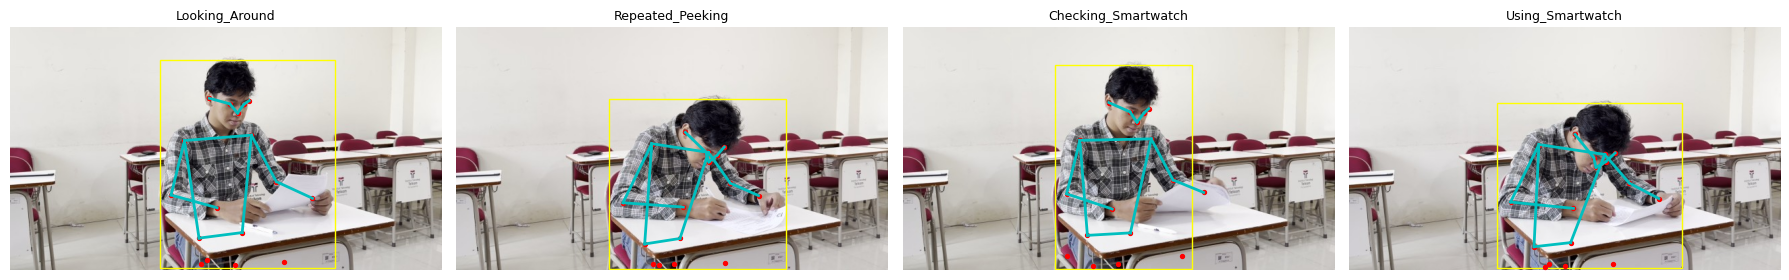

In [10]:
SKELETON = [(0, 1), (0, 2), (1, 3), (2, 4), (5, 6), (5, 7), (7, 9), (6, 8), (8, 10), (5, 11), (6, 12), (11, 12)]

def frame_at(path, idx):
    cap = cv2.VideoCapture(path); cap.set(cv2.CAP_PROP_POS_FRAMES, idx); f = cap.read()[1]; cap.release()
    return to_rgb(f, True)

fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
show = ["Looking_Around", "Repeated_Peeking", "Checking_Smartwatch", "Using_Smartwatch"]
for a, beh in zip(ax, show):
    w = win_train[(win_train["behavior"] == beh) & (win_train["subject"] == 1) & (win_train["angle"] == "front")].index[3]
    img = frame_at(train_videos.set_index("video").loc[win_train.loc[w, "video"], "path"], win_train.loc[w, "start"])
    k = kp_train[w, 0]; x, y, bw, bh = box_train[w]
    a.imshow(img); a.add_patch(plt.Rectangle((x, y), bw, bh, fill=False, color="yellow"))
    for i, j in SKELETON:
        a.plot(k[[i, j], 0], k[[i, j], 1], "c-", lw=2)
    a.scatter(k[:, 0], k[:, 1], s=8, c="red"); a.set_title(beh, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

# Feature Engineering

### Fitur pose per window
Koordinat keypoint dinormalisasi dengan tinggi box orang supaya tidak bergantung pada jarak kamera. Untuk setiap seri waktu (10 frame) dihitung mean, std, min, max, dan rata-rata perubahan antar frame:
- Kepala: posisi hidung relatif terhadap tengah bahu, arah toleh (hidung relatif ke tengah telinga dan mata, dibagi lebar bahu), selisih visibilitas telinga kiri/kanan, dan kemiringan kepala (mata vs telinga).
- Tangan: posisi pergelangan tangan relatif terhadap bahu, jarak pergelangan ke hidung (melihat smartwatch), jarak antar pergelangan, dan tinggi siku.
- Badan: lebar dan kemiringan bahu, posisi bahu dalam box (membungkuk ke bawah meja), dan rata-rata skor keypoint.
- Kecepatan keypoint kepala, lengan kiri, lengan kanan, dan badan.
- Box: rasio aspek, tinggi, dan posisi vertikal box.

In [11]:
NOSE, LEYE, REYE, LEAR, REAR, LSH, RSH, LEL, REL, LWR, RWR, LHIP, RHIP = range(13)

def pose_features(kp, box):
    bx, by, bw, bh = [box[:, i][:, None, None] for i in range(4)]
    x, y, s = (kp[..., 0] - bx) / bh, (kp[..., 1] - by) / bh, kp[..., 2]
    msx, msy = (x[..., LSH] + x[..., RSH]) / 2, (y[..., LSH] + y[..., RSH]) / 2
    sh_w = np.abs(x[..., LSH] - x[..., RSH]) + 1e-3
    series = {
        "nose_dx": x[..., NOSE] - msx, "nose_dy": y[..., NOSE] - msy,
        "head_yaw": (x[..., NOSE] - (x[..., LEAR] + x[..., REAR]) / 2) / sh_w,
        "eye_yaw": (x[..., NOSE] - (x[..., LEYE] + x[..., REYE]) / 2) / sh_w,
        "eye_ear_dy": (y[..., LEYE] + y[..., REYE]) / 2 - (y[..., LEAR] + y[..., REAR]) / 2,
        "ear_vis_diff": s[..., LEAR] - s[..., REAR], "nose_score": s[..., NOSE],
        "lwr_dx": x[..., LWR] - msx, "lwr_dy": y[..., LWR] - msy, "rwr_dx": x[..., RWR] - msx, "rwr_dy": y[..., RWR] - msy,
        "lwr_nose": np.hypot(x[..., LWR] - x[..., NOSE], y[..., LWR] - y[..., NOSE]),
        "rwr_nose": np.hypot(x[..., RWR] - x[..., NOSE], y[..., RWR] - y[..., NOSE]),
        "wr_dist": np.hypot(x[..., LWR] - x[..., RWR], y[..., LWR] - y[..., RWR]),
        "lel_dy": y[..., LEL] - msy, "rel_dy": y[..., REL] - msy,
        "lwr_score": s[..., LWR], "rwr_score": s[..., RWR],
        "sh_w": sh_w, "sh_tilt": y[..., LSH] - y[..., RSH], "ms_y": msy, "ms_x": msx,
        "hip_y": (y[..., LHIP] + y[..., RHIP]) / 2 - msy, "kp_score": s.mean(-1),
    }
    f = {}
    for k, v in series.items():
        f[f"{k}_mean"], f[f"{k}_std"], f[f"{k}_min"], f[f"{k}_max"] = v.mean(1), v.std(1), v.min(1), v.max(1)
        f[f"{k}_dabs"] = np.abs(np.diff(v, axis=1)).mean(1)
    vel = np.hypot(np.diff(x, axis=1), np.diff(y, axis=1))
    for name, idx in (("head", [0, 1, 2, 3, 4]), ("arm_l", [7, 9]), ("arm_r", [8, 10]), ("torso", [5, 6, 11, 12])):
        f[f"vel_{name}_mean"], f[f"vel_{name}_max"] = vel[..., idx].mean(-1).mean(1), vel[..., idx].mean(-1).max(1)
    f["box_ar"], f["box_h"] = box[:, 2] / box[:, 3], box[:, 3] / TEST_H
    f["box_cy"] = (box[:, 1] + box[:, 3] / 2) / TEST_H
    return pd.DataFrame(f)

X_win_train = pose_features(kp_train, box_train)
X_win_test = pose_features(kp_test, box_test)
print(f"fitur per window: {X_win_train.shape[1]} | train: {len(X_win_train)} | test: {len(X_win_test)}")

fitur per window: 131 | train: 6456 | test: 1515


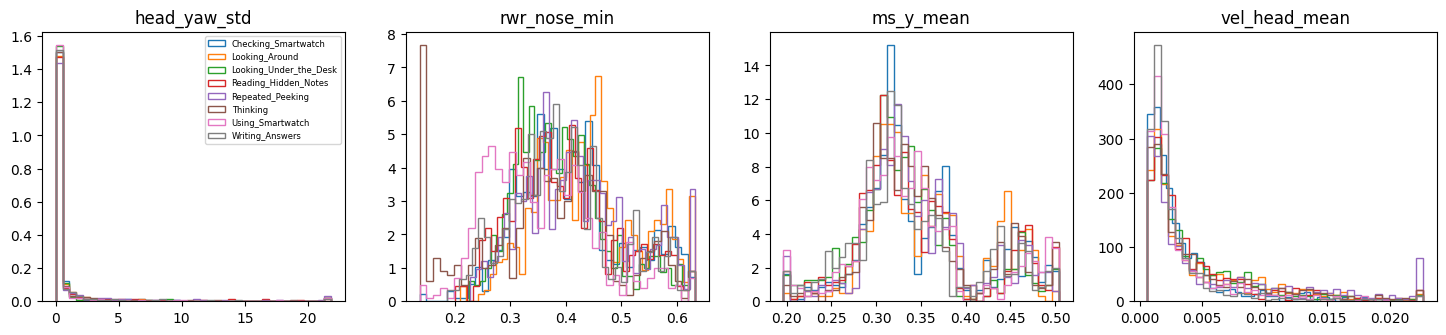

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for a, col in zip(ax, ["head_yaw_std", "rwr_nose_min", "ms_y_mean", "vel_head_mean"]):
    for b in BEHAVIORS:
        a.hist(X_win_train.loc[win_train["behavior"] == b, col].clip(*X_win_train[col].quantile([0.01, 0.99])),
               bins=40, density=True, histtype="step", label=b)
    a.set_title(col)
ax[0].legend(fontsize=6)
plt.show()

# Struktur Test: Angle dan Subjek

### Angle setiap video test
Classifier logistic regression dilatih pada rata-rata fitur pose per video train (front vs side), lalu dipakai untuk video test. Akurasi dicek dengan GroupKFold per subjek.

In [13]:
win_test = win_test.merge(test_chains, on="id", how="left")
assert win_test["chain"].notna().all()
vid_train_mean = X_win_train.groupby(win_train["video"]).mean()
vid_train_angle = win_train.drop_duplicates("video").set_index("video").loc[vid_train_mean.index, "angle"]
vid_train_subj = win_train.drop_duplicates("video").set_index("video").loc[vid_train_mean.index, "subject"]

def make_angle_clf():
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))

from sklearn.model_selection import GroupKFold, cross_val_score
acc = cross_val_score(make_angle_clf(), vid_train_mean, vid_train_angle, groups=vid_train_subj, cv=GroupKFold(5))
print("akurasi angle (CV per subjek):", acc.round(3), acc.mean().round(4))

chain_mean = X_win_test.groupby(win_test["chain"].values).mean()
chain_info = pd.DataFrame({"chain": chain_mean.index, "len": chain_len.loc[chain_mean.index].values,
                           "angle": make_angle_clf().fit(vid_train_mean, vid_train_angle).predict(chain_mean)})
print(chain_info["angle"].value_counts().to_dict())

akurasi angle (CV per subjek): [1. 1. 1. 1. 1.] 1.0
{'front': 49, 'side': 48}


### Pengelompokan subjek
Subjek dikenali dari histogram warna HSV pada crop orang (box RT-DETR), dirata-rata dari 4 sequence per rantai. Untuk setiap angle, rantai dikelompokkan dengan Ward clustering lalu diperhalus dengan penugasan berkapasitas (setiap subjek punya 8 video per angle). Rantai pendek (potongan video yang terputus) di angle yang sama digabung dengan pasangan terdekatnya.

In [14]:
def color_hist(seq_id, box):
    img = cv2.imread(f"{DATA_DIR}/test/{seq_id}/16.jpg")
    x, y, w, h = [int(v) for v in box]
    crop = cv2.cvtColor(img[max(y, 0) : y + h, max(x, 0) : x + w], cv2.COLOR_BGR2HSV)
    h_ = cv2.calcHist([crop], [0, 1, 2], None, [12, 4, 4], [0, 180, 0, 256, 0, 256]).ravel()
    return np.sqrt(h_ / h_.sum())

box_by_id = dict(zip(win_test["id"], box_test))
chain_hist = []
for c in chain_info["chain"]:
    g = test_chains[test_chains["chain"] == c].sort_values("pos")
    sel = g.iloc[np.linspace(0, len(g) - 1, 4).astype(int)]
    chain_hist.append(np.mean([color_hist(i, box_by_id[i]) for i in sel["id"]], axis=0))
chain_hist = np.stack(chain_hist)

# gabungkan rantai pendek di angle yang sama dengan rantai pendek terdekat
chain_info["video_id"] = chain_info["chain"]
SHORT = 10
for a in chain_info["angle"].unique():
    shorts = list(chain_info.index[(chain_info["angle"] == a) & (chain_info["len"] < SHORT)])
    while len(shorts) >= 2:
        d = pairwise_distances(chain_hist[shorts])
        np.fill_diagonal(d, np.inf)
        i, j = np.unravel_index(d.argmin(), d.shape)
        chain_info.loc[shorts[j], "video_id"] = chain_info.loc[shorts[i], "video_id"]
        print(f"gabung rantai {chain_info.loc[shorts[j], 'chain']} ke {chain_info.loc[shorts[i], 'chain']} ({a})")
        shorts = [s for k, s in enumerate(shorts) if k not in (i, j)]

def capacitated_cluster(X, k, cap, n_iter=20):
    lab = AgglomerativeClustering(k, linkage="ward").fit_predict(X)
    for _ in range(n_iter):
        cent = np.stack([X[lab == c].mean(0) for c in range(k)])
        cost = np.repeat(pairwise_distances(X, cent) ** 2, cap, axis=1)   # setiap cluster punya `cap` slot
        _, slot = linear_sum_assignment(cost)
        new = slot // cap
        if (new == lab).all():
            break
        lab = new
    return lab

video_hist = pd.DataFrame(chain_hist).groupby(chain_info["video_id"].values).mean()
video_angle = chain_info.groupby("video_id")["angle"].first().loc[video_hist.index]
video_group = pd.Series(index=video_hist.index, dtype=object)
for a in video_angle.unique():
    idx = video_hist.index[video_angle == a]
    k = int(round(len(idx) / 8))
    lab = capacitated_cluster(video_hist.loc[idx].values, k, cap=int(np.ceil(len(idx) / k)))
    video_group.loc[idx] = [f"{a}_{l}" for l in lab]
chain_info["group"] = chain_info["video_id"].map(video_group)
chain_info["subject_group"] = chain_info["group"].str.split("_").str[1]
print("video per kelompok:", video_group.value_counts().sort_index().to_dict())

gabung rantai 11 ke 4 (front)
video per kelompok: {'front_0': 8, 'front_1': 8, 'front_2': 8, 'front_3': 8, 'front_4': 8, 'front_5': 8, 'side_0': 8, 'side_1': 8, 'side_2': 8, 'side_3': 8, 'side_4': 8, 'side_5': 8}


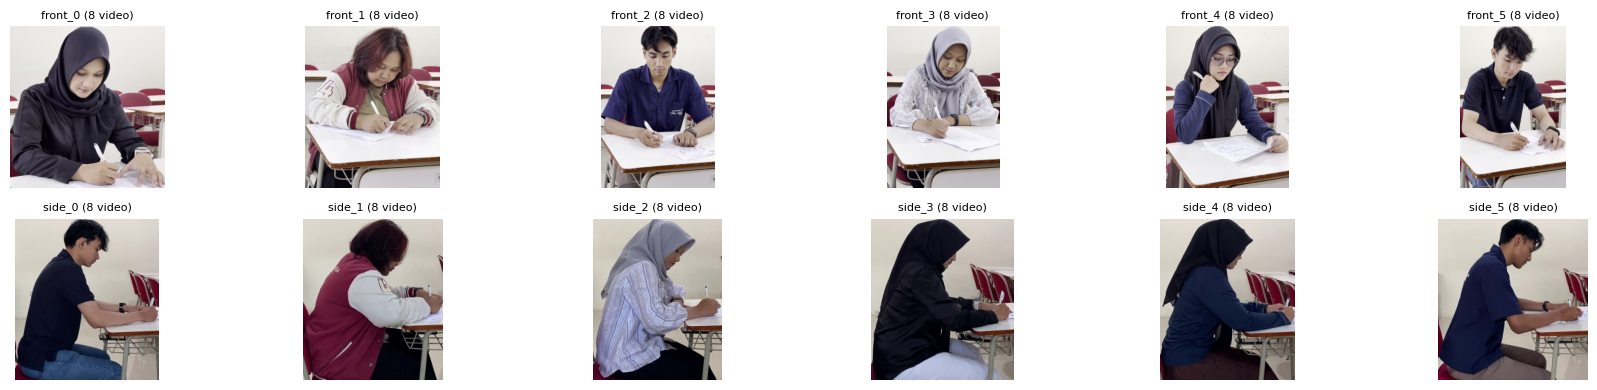

In [15]:
fig, ax = plt.subplots(2, 6, figsize=(18, 4))
for a, (gname, g) in zip(ax.ravel(), chain_info.groupby("group")):
    sid = test_chains[test_chains["chain"] == g["chain"].iloc[0]]["id"].iloc[0]
    x, y, w, h = [int(v) for v in box_by_id[sid]]
    a.imshow(cv2.cvtColor(cv2.imread(f"{DATA_DIR}/test/{sid}/16.jpg")[y : y + h, x : x + w], cv2.COLOR_BGR2RGB))
    a.set_title(f"{gname} ({g['video_id'].nunique()} video)", fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

### Fitur konteks video dan kelompok
Satu detik sering tidak cukup untuk membedakan perilaku, sedangkan video utuh tersedia di train (dan direkonstruksi di test):
- vid_*: rata-rata fitur semua window dalam video.
- dev_*: selisih window terhadap rata-rata videonya.
- vidz_*: rata-rata video yang di-z-score terhadap semua video dari subjek dan angle yang sama. Ini menghilangkan gaya gerak dan posisi kamera tiap subjek, sehingga yang tersisa adalah perbedaan antar perilaku.

In [16]:
def context_features(X, video, group):
    vm = X.groupby(video).transform("mean")
    gm = X.groupby(group).transform("mean")
    gs = X.groupby(group).transform("std").fillna(0) + 1e-6
    return pd.concat([X, vm.add_prefix("vid_"), (X - vm).add_prefix("dev_"), ((vm - gm) / gs).add_prefix("vidz_")], axis=1)

train_video_key = win_train["video"].values
train_group_key = (win_train["subject"].astype(str) + "_" + win_train["angle"]).values
ci = chain_info.set_index("chain")
test_video_key = win_test["chain"].map(ci["video_id"]).values
test_group_key = win_test["chain"].map(ci["group"]).values

X_train = context_features(X_win_train, train_video_key, train_group_key)
X_test = context_features(X_win_test, test_video_key, test_group_key)
FEATURES = list(X_train.columns)
print(f"total fitur: {len(FEATURES)}")

total fitur: 524


# Classifier Models

### Setup parameter dan validasi
Target model adalah 8 perilaku (multiclass), karena perilaku dalam satu kelas sangat berbeda satu sama lain (contoh: Thinking vs Checking Smartwatch). Probabilitas cheat = jumlah probabilitas 4 perilaku cheat. Validasi memakai StratifiedGroupKFold per subjek, dan fitur konteks memakai video serta kelompok subjek-angle yang asli.

Skor yang dilaporkan:
- clip: per window 1 detik, threshold 0.5.
- video: rata-rata log-probabilitas window per video, lalu threshold 0.5. Label video dipakai untuk semua sequence-nya.
- video_bal: per subjek-angle, 4 video dengan probabilitas cheat tertinggi = cheat.
- video_hung: per subjek-angle, setiap perilaku ditugaskan tepat ke satu video (Hungarian assignment).

In [17]:
N_FOLDS = 5
SEEDS = [42, 43, 44]
LGBM_PARAMS = dict(
    objective="multiclass", n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
    deterministic=True, force_row_wise=True, verbose=-1,
)
y_beh = win_train["behavior"].map({b: i for i, b in enumerate(BEHAVIORS)}).values
y_bin = win_train["label"].values

def f1_macro(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def fit_predict(X_tr, y_tr, X_te):
    return np.mean([LGBMClassifier(**LGBM_PARAMS, random_state=s).fit(X_tr, y_tr).predict_proba(X_te) for s in SEEDS], axis=0)

def video_probs(P, video_key):
    logP = pd.DataFrame(np.log(P + 1e-9)).groupby(video_key).mean()
    Pv = np.exp(logP.values)
    return pd.DataFrame(Pv / Pv.sum(1, keepdims=True), index=logP.index, columns=BEHAVIORS)

def assign_groups(Pv, groups, mode):
    # Pv: DataFrame probabilitas per video; groups: Series video -> kelompok subjek-angle
    out = pd.Series(0, index=Pv.index)
    for _, vids in groups.groupby(groups):
        p = Pv.loc[vids.index].values
        if mode == "bal":
            top = np.argsort(-p[:, CHEAT_IDX].sum(1))[: len(p) // 2]
            out.loc[vids.index[top]] = 1
        else:
            reps = int(np.ceil(len(p) / len(BEHAVIORS)))
            r, c = linear_sum_assignment(-np.log(np.tile(p, (1, reps)) + 1e-9))
            out.loc[vids.index[r]] = [int(c_ % len(BEHAVIORS) in CHEAT_IDX) for c_ in c]
    return out

### LGBM Classifier

In [18]:
vids = win_train.drop_duplicates("video").reset_index(drop=True)
oof = np.zeros((len(X_train), len(BEHAVIORS)))
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for fold, (tr_v, va_v) in enumerate(sgkf.split(vids, vids["label"], vids["subject"])):
    va = win_train["video"].isin(vids.loc[va_v, "video"]).values
    oof[va] = fit_predict(X_train[~va], y_beh[~va], X_train[va])
    print(f"fold {fold}: subjects={sorted(vids.loc[va_v, 'subject'].unique().tolist())} "
          f"clip F1-macro={f1_macro(y_bin[va], oof[va][:, CHEAT_IDX].sum(1) > 0.5):.4f}")

Pv_oof = video_probs(oof, train_video_key)
vmeta = win_train.drop_duplicates("video").set_index("video").loc[Pv_oof.index]
vgroups = vmeta["subject"].astype(str) + "_" + vmeta["angle"]
scores = {
    "clip": f1_macro(y_bin, oof[:, CHEAT_IDX].sum(1) > 0.5),
    "video": f1_macro(vmeta["label"], Pv_oof[CHEAT_B].sum(1) > 0.5),
    "video_bal": f1_macro(vmeta["label"], assign_groups(Pv_oof, vgroups, "bal")),
    "video_hung": f1_macro(vmeta["label"], assign_groups(Pv_oof, vgroups, "hung")),
}
print({k: round(v, 4) for k, v in scores.items()})

fold 0: subjects=[3, 7, 9, 10, 21, 22] clip F1-macro=0.8027


fold 1: subjects=[8, 13, 14, 17, 18] clip F1-macro=0.8617


fold 2: subjects=[1, 2, 11, 16, 23] clip F1-macro=0.7556


fold 3: subjects=[4, 15, 19, 24, 25] clip F1-macro=0.7737


fold 4: subjects=[5, 6, 12, 20, 26] clip F1-macro=0.8386


{'clip': 0.8063, 'video': 0.8049, 'video_bal': 0.8077, 'video_hung': 0.8846}


### Analisis error per perilaku
Confusion matrix 8 perilaku pada level video (argmax) dan akurasi biner setelah Hungarian assignment per perilaku dan angle.

In [19]:
vmeta = vmeta.assign(pred_beh=Pv_oof.values.argmax(1), hung=assign_groups(Pv_oof, vgroups, "hung"))
cm = pd.DataFrame(confusion_matrix(vmeta["behavior"].map(BEHAVIORS.index), vmeta["pred_beh"], labels=range(len(BEHAVIORS))),
                  index=BEHAVIORS, columns=[b[:10] for b in BEHAVIORS])
print(cm)
print("\nakurasi biner (Hungarian) per perilaku x angle:")
print(vmeta.assign(ok=vmeta["hung"] == vmeta["label"]).pivot_table(index="behavior", columns="angle", values="ok").round(3))

                        Checking_S  Looking_Ar  Looking_Un  Reading_Hi  \
Checking_Smartwatch             33           1           1           3   
Looking_Around                   0          31           2           0   
Looking_Under_the_Desk           0           0          50           2   
Reading_Hidden_Notes             7           0           2          40   
Repeated_Peeking                 0          14           0           1   
Thinking                         2           0           2           2   
Using_Smartwatch                 5           0           0           0   
Writing_Answers                  2           0           6           6   

                        Repeated_P  Thinking  Using_Smar  Writing_An  
Checking_Smartwatch              2         3           7           2  
Looking_Around                  15         1           0           3  
Looking_Under_the_Desk           0         0           0           0  
Reading_Hidden_Notes             0         2     

### Final model
Melatih ulang LGBM (3 seed) di seluruh data train dengan parameter yang sama seperti saat CV.

In [20]:
final_models = [LGBMClassifier(**LGBM_PARAMS, random_state=s).fit(X_train, y_beh) for s in SEEDS]
joblib.dump(final_models, "models/main_model.pkl")
print("models:", len(final_models), "| n_estimators =", LGBM_PARAMS["n_estimators"])

models: 3 | n_estimators = 300


### Feature Importance for LGBM

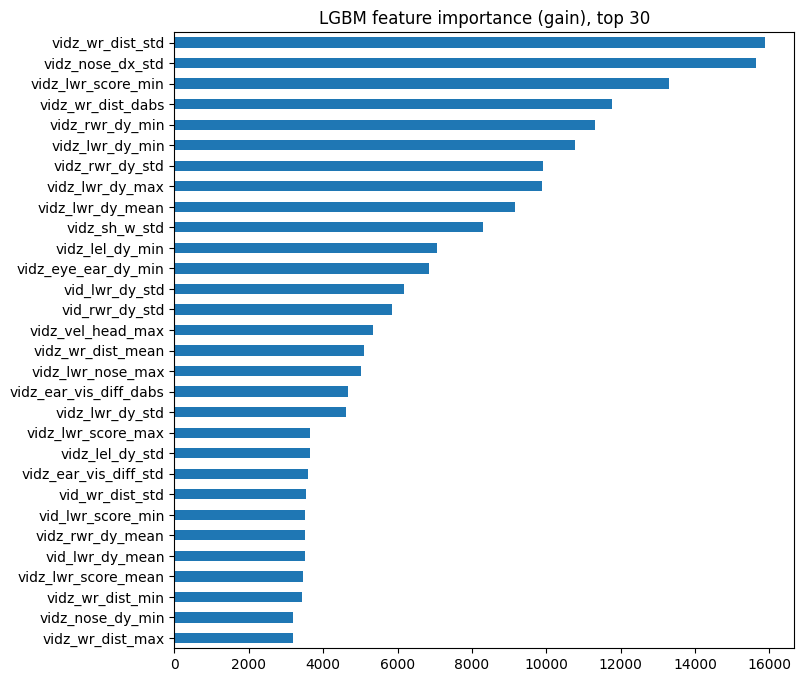

dev       0.002
vid       0.213
vidz      0.780
window    0.006
dtype: float64

In [21]:
importance = pd.Series(np.mean([m.booster_.feature_importance(importance_type="gain") for m in final_models], 0), index=FEATURES)
importance.sort_values().tail(30).plot(kind="barh", figsize=(8, 8), title="LGBM feature importance (gain), top 30")
plt.show()
grp = importance.groupby(importance.index.map(lambda c: c.split("_")[0] if c.split("_")[0] in ("vid", "dev", "vidz") else "window")).sum()
(grp / grp.sum()).round(3)

# Postprocessing

### Agregasi per video dan Hungarian assignment
Probabilitas 8 perilaku setiap sequence test digabung per video hasil rekonstruksi. Lalu di setiap kelompok subjek-angle, perilaku ditugaskan ke video dengan Hungarian assignment (pendekatan terbaik di CV). Label video diberikan ke semua sequence dalam video tersebut.

In [22]:
P_test = np.mean([m.predict_proba(X_test[FEATURES]) for m in final_models], axis=0)
Pv_test = video_probs(P_test, test_video_key)
test_vgroups = chain_info.drop_duplicates("video_id").set_index("video_id")["group"].loc[Pv_test.index]

video_label = {
    "hung": assign_groups(Pv_test, test_vgroups, "hung"),
    "bal": assign_groups(Pv_test, test_vgroups, "bal"),
    "video": (Pv_test[CHEAT_B].sum(1) > 0.5).astype(int),
}
win_test["clip_label"] = (P_test[:, CHEAT_IDX].sum(1) > 0.5).astype(int)
for k, v in video_label.items():
    win_test[f"{k}_label"] = pd.Series(test_video_key).map(v).values
print("cheat share per metode:", win_test[[c for c in win_test.columns if c.endswith("_label")]].mean().round(3).to_dict())
print("kesepakatan hung vs video:", (win_test["hung_label"] == win_test["video_label"]).mean().round(3))
print("perilaku terprediksi per video (argmax):", Pv_test.idxmax(1).value_counts().to_dict())

cheat share per metode: {'clip_label': 0.502, 'hung_label': 0.502, 'bal_label': 0.506, 'video_label': 0.502}
kesepakatan hung vs video: 0.828
perilaku terprediksi per video (argmax): {'Writing_Answers': 15, 'Reading_Hidden_Notes': 13, 'Looking_Under_the_Desk': 13, 'Using_Smartwatch': 12, 'Looking_Around': 12, 'Repeated_Peeking': 12, 'Thinking': 10, 'Checking_Smartwatch': 9}


# Submission

In [23]:
def make_submission(col, path):
    sub = sample_sub[["id"]].merge(win_test[["id", col]].rename(columns={col: "label"}), on="id", how="left")
    assert len(sub) == len(sample_sub) and sub["label"].notna().all()
    sub["label"] = sub["label"].astype(int)
    sub.to_csv(path, index=False)
    return sub

submission = make_submission("hung_label", "submissions/submission_main.csv")              # utama
make_submission("video_label", "submissions/submission_main_video.csv")                     # cadangan tanpa assignment kelompok
submission["label"].value_counts()

label
1    760
0    755
Name: count, dtype: int64